In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [8]:
!pip install -q -U datasets
import pandas as pd
from datasets import load_dataset

ds = load_dataset("nyu-mll/glue", "qqp")
df = pd.concat([ds["train"].to_pandas(), ds["validation"].to_pandas()], ignore_index=True)
df = df.rename(columns={"label": "is_duplicate"})[["question1", "question2", "is_duplicate"]]
print(df.shape)
df.head()

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

qqp/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 33.6MB            

qqp/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

qqp/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.73MB            

qqp/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

qqp/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 36.7MB            

... (2 outputs left out)

Generating validation split:   0%|          | 0/40430 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/390965 [00:00<?, ? examples/s]

(404276, 3)


,question1,question2,is_duplicate
0,How is the life of a math student? Could you d...,Which level of prepration is enough for the ex...,0
1,How do I control my horny emotions?,How do you control your horniness?,1
2,What causes stool color to change to yellow?,What can cause stool to come out as little balls?,0
3,What can one do after MBBS?,What do i do after my MBBS ?,1
4,Where can I find a power outlet for my laptop ...,"Would a second airport in Sydney, Australia be...",0


In [11]:
import numpy as np
import pandas as pd
from datasets import load_dataset

ds = load_dataset("nyu-mll/glue", "qqp")
df = pd.concat([ds["train"].to_pandas(), ds["validation"].to_pandas()], ignore_index=True)
df = df.rename(columns={"label": "is_duplicate"})[["question1", "question2", "is_duplicate"]]

# Interleave q1, q2, q1, q2... so ids are assigned in order of first appearance
interleaved = np.empty(len(df) * 2, dtype=object)
interleaved[0::2] = df["question1"].values
interleaved[1::2] = df["question2"].values

codes, uniques = pd.factorize(interleaved)
codes = codes + 1  # start at 1, like the original

df.insert(0, "id", np.arange(len(df)))
df.insert(1, "qid1", codes[0::2])
df.insert(2, "qid2", codes[1::2])

print(df.shape)
df.head()

(404276, 6)


,id,qid1,qid2,question1,question2,is_duplicate
0,0,1,2,How is the life of a math student? Could you d...,Which level of prepration is enough for the ex...,0
1,1,3,4,How do I control my horny emotions?,How do you control your horniness?,1
2,2,5,6,What causes stool color to change to yellow?,What can cause stool to come out as little balls?,0
3,3,7,8,What can one do after MBBS?,What do i do after my MBBS ?,1
4,4,9,10,Where can I find a power outlet for my laptop ...,"Would a second airport in Sydney, Australia be...",0


In [12]:
df.shape

(404276, 6)

In [13]:
df.head()

,id,qid1,qid2,question1,question2,is_duplicate
0,0,1,2,How is the life of a math student? Could you d...,Which level of prepration is enough for the ex...,0
1,1,3,4,How do I control my horny emotions?,How do you control your horniness?,1
2,2,5,6,What causes stool color to change to yellow?,What can cause stool to come out as little balls?,0
3,3,7,8,What can one do after MBBS?,What do i do after my MBBS ?,1
4,4,9,10,Where can I find a power outlet for my laptop ...,"Would a second airport in Sydney, Australia be...",0


In [14]:
new_df = df.sample(30000,random_state=2)

In [15]:
new_df.isnull().sum()

,0
id,0
qid1,0
qid2,0
question1,0
question2,0
is_duplicate,0


In [16]:
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate
134596,134596,22369,215114,I can see a contacts display picture on WhatsA...,I deleted a contact from my phone can he still...,0
27109,27109,50287,50288,What is the significance of 2^32 in computers?,Is a 3:2 program for computer science at Reed ...,0
369694,369694,405766,81442,Which is the best Harry Potter book?,What's the best Harry Potter book?,1
292958,292958,121929,414456,What makes a woman or girl unattractive?,Does being fat make you unattractive?,0
93000,93000,155554,155555,How are the placements for M Tech Mechanical s...,How is placement scenario for m.tech students(...,0


In [17]:
new_df.isnull().sum()

,0
id,0
qid1,0
qid2,0
question1,0
question2,0
is_duplicate,0


In [18]:
new_df.duplicated().sum()

np.int64(0)

is_duplicate
0    18939
1    11061
Name: count, dtype: int64
is_duplicate
0    63.13
1    36.87
Name: count, dtype: float64


<Axes: xlabel='is_duplicate'>

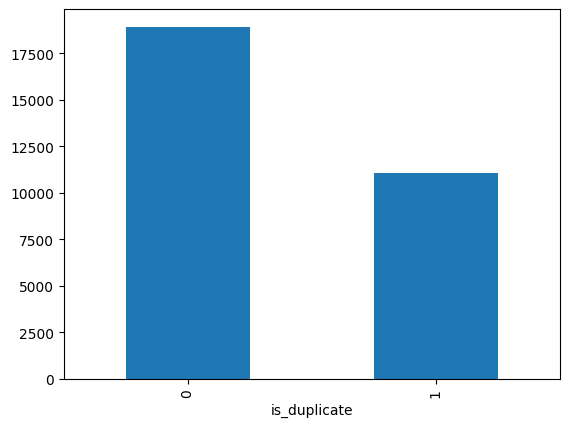

In [19]:
# Distribution of duplicate and non-duplicate questions

print(new_df['is_duplicate'].value_counts())
print((new_df['is_duplicate'].value_counts()/new_df['is_duplicate'].count())*100)
new_df['is_duplicate'].value_counts().plot(kind='bar')

In [20]:
# Repeated questions

qid = pd.Series(new_df['qid1'].tolist() + new_df['qid2'].tolist())
print('Number of unique questions',np.unique(qid).shape[0])
x = qid.value_counts()>1
print('Number of questions getting repeated',x[x].shape[0])

Number of unique questions 55407
Number of questions getting repeated 3410


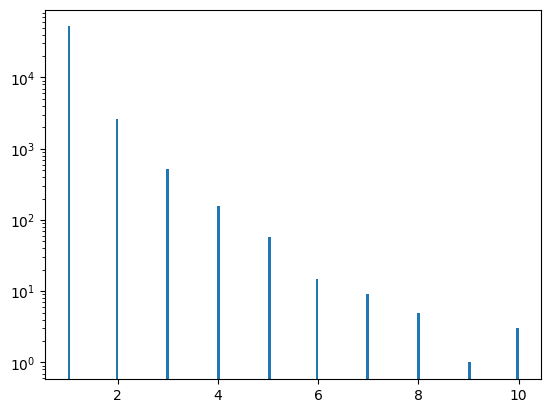

In [21]:
# Repeated questions histogram

plt.hist(qid.value_counts().values,bins=160)
plt.yscale('log')
plt.show()

In [22]:
# Feature Engineering

new_df['q1_len'] = new_df['question1'].str.len()
new_df['q2_len'] = new_df['question2'].str.len()

In [23]:
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len
134596,134596,22369,215114,I can see a contacts display picture on WhatsA...,I deleted a contact from my phone can he still...,0,163,71
27109,27109,50287,50288,What is the significance of 2^32 in computers?,Is a 3:2 program for computer science at Reed ...,0,46,63
369694,369694,405766,81442,Which is the best Harry Potter book?,What's the best Harry Potter book?,1,36,34
292958,292958,121929,414456,What makes a woman or girl unattractive?,Does being fat make you unattractive?,0,40,37
93000,93000,155554,155555,How are the placements for M Tech Mechanical s...,How is placement scenario for m.tech students(...,0,68,83


In [24]:
new_df['q1_num_words'] = new_df['question1'].apply(lambda row: len(row.split(" ")))
new_df['q2_num_words'] = new_df['question2'].apply(lambda row: len(row.split(" ")))
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words
134596,134596,22369,215114,I can see a contacts display picture on WhatsA...,I deleted a contact from my phone can he still...,0,163,71,32,16
27109,27109,50287,50288,What is the significance of 2^32 in computers?,Is a 3:2 program for computer science at Reed ...,0,46,63,8,12
369694,369694,405766,81442,Which is the best Harry Potter book?,What's the best Harry Potter book?,1,36,34,7,6
292958,292958,121929,414456,What makes a woman or girl unattractive?,Does being fat make you unattractive?,0,40,37,7,6
93000,93000,155554,155555,How are the placements for M Tech Mechanical s...,How is placement scenario for m.tech students(...,0,68,83,12,11


In [25]:
def common_words(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" ")))
    return len(w1 & w2)

In [26]:
new_df['word_common'] = new_df.apply(common_words, axis=1)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common
134596,134596,22369,215114,I can see a contacts display picture on WhatsA...,I deleted a contact from my phone can he still...,0,163,71,32,16,7
27109,27109,50287,50288,What is the significance of 2^32 in computers?,Is a 3:2 program for computer science at Reed ...,0,46,63,8,12,1
369694,369694,405766,81442,Which is the best Harry Potter book?,What's the best Harry Potter book?,1,36,34,7,6,5
292958,292958,121929,414456,What makes a woman or girl unattractive?,Does being fat make you unattractive?,0,40,37,7,6,1
93000,93000,155554,155555,How are the placements for M Tech Mechanical s...,How is placement scenario for m.tech students(...,0,68,83,12,11,4


In [27]:
def total_words(row):
    w1 = set(map(lambda word: word.lower().strip(), row['question1'].split(" ")))
    w2 = set(map(lambda word: word.lower().strip(), row['question2'].split(" ")))
    return (len(w1) + len(w2))

In [28]:
new_df['word_total'] = new_df.apply(total_words, axis=1)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total
134596,134596,22369,215114,I can see a contacts display picture on WhatsA...,I deleted a contact from my phone can he still...,0,163,71,32,16,7,43
27109,27109,50287,50288,What is the significance of 2^32 in computers?,Is a 3:2 program for computer science at Reed ...,0,46,63,8,12,1,20
369694,369694,405766,81442,Which is the best Harry Potter book?,What's the best Harry Potter book?,1,36,34,7,6,5,13
292958,292958,121929,414456,What makes a woman or girl unattractive?,Does being fat make you unattractive?,0,40,37,7,6,1,13
93000,93000,155554,155555,How are the placements for M Tech Mechanical s...,How is placement scenario for m.tech students(...,0,68,83,12,11,4,23


In [29]:
new_df['word_share'] = round(new_df['word_common']/new_df['word_total'],2)
new_df.head()

,id,qid1,qid2,question1,question2,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share
134596,134596,22369,215114,I can see a contacts display picture on WhatsA...,I deleted a contact from my phone can he still...,0,163,71,32,16,7,43,0.16
27109,27109,50287,50288,What is the significance of 2^32 in computers?,Is a 3:2 program for computer science at Reed ...,0,46,63,8,12,1,20,0.05
369694,369694,405766,81442,Which is the best Harry Potter book?,What's the best Harry Potter book?,1,36,34,7,6,5,13,0.38
292958,292958,121929,414456,What makes a woman or girl unattractive?,Does being fat make you unattractive?,0,40,37,7,6,1,13,0.08
93000,93000,155554,155555,How are the placements for M Tech Mechanical s...,How is placement scenario for m.tech students(...,0,68,83,12,11,4,23,0.17


minimum characters 1
maximum characters 627
average num of characters 59


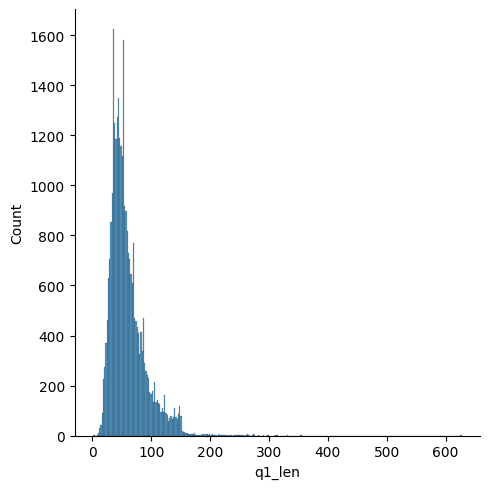

In [30]:
# Analysis of features
sns.displot(new_df['q1_len'])
print('minimum characters',new_df['q1_len'].min())
print('maximum characters',new_df['q1_len'].max())
print('average num of characters',int(new_df['q1_len'].mean()))

minimum characters 2
maximum characters 1151
average num of characters 60


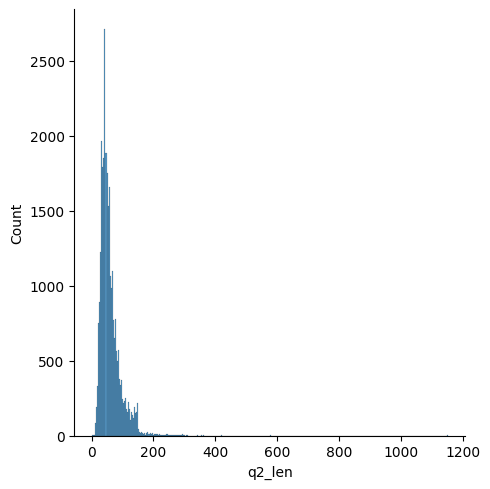

In [31]:
sns.displot(new_df['q2_len'])
print('minimum characters',new_df['q2_len'].min())
print('maximum characters',new_df['q2_len'].max())
print('average num of characters',int(new_df['q2_len'].mean()))

minimum words 1
maximum words 125
average num of words 10


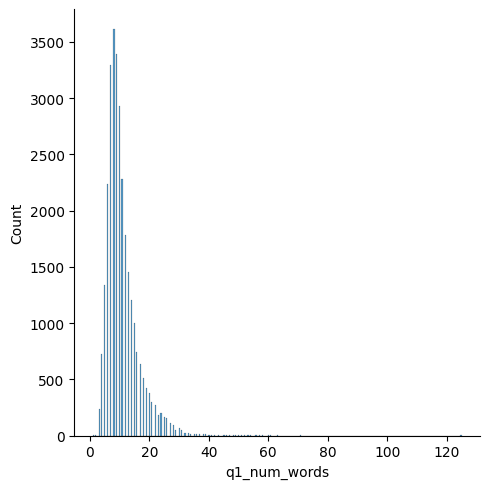

In [32]:
sns.displot(new_df['q1_num_words'])
print('minimum words',new_df['q1_num_words'].min())
print('maximum words',new_df['q1_num_words'].max())
print('average num of words',int(new_df['q1_num_words'].mean()))

minimum words 1
maximum words 237
average num of words 11


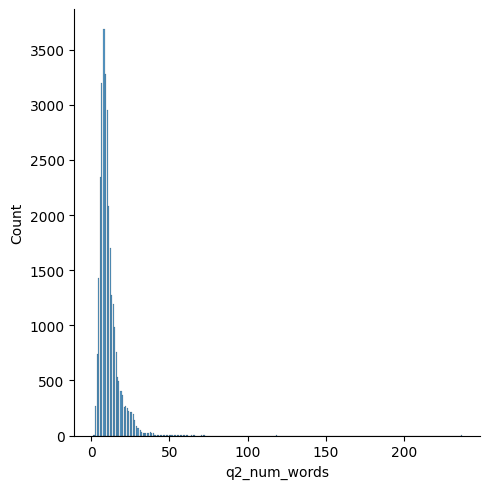

In [33]:
sns.displot(new_df['q2_num_words'])
print('minimum words',new_df['q2_num_words'].min())
print('maximum words',new_df['q2_num_words'].max())
print('average num of words',int(new_df['q2_num_words'].mean()))

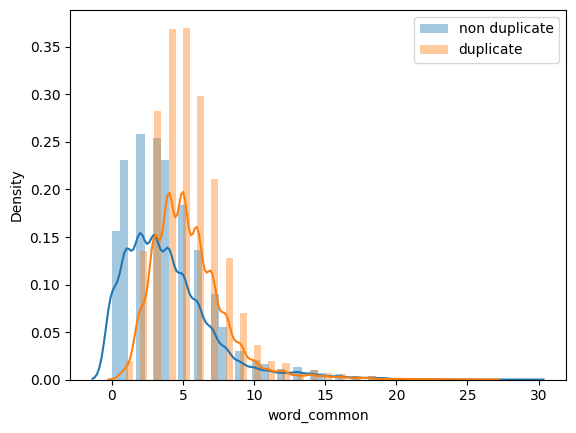

In [34]:
# common words
sns.distplot(new_df[new_df['is_duplicate'] == 0]['word_common'],label='non duplicate')
sns.distplot(new_df[new_df['is_duplicate'] == 1]['word_common'],label='duplicate')
plt.legend()
plt.show()

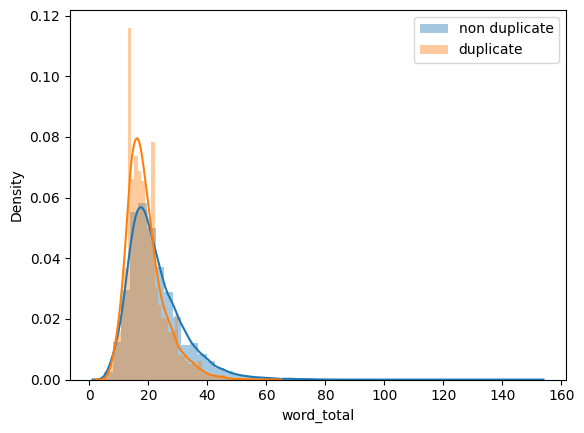

In [35]:
# total words
sns.distplot(new_df[new_df['is_duplicate'] == 0]['word_total'],label='non duplicate')
sns.distplot(new_df[new_df['is_duplicate'] == 1]['word_total'],label='duplicate')
plt.legend()
plt.show()

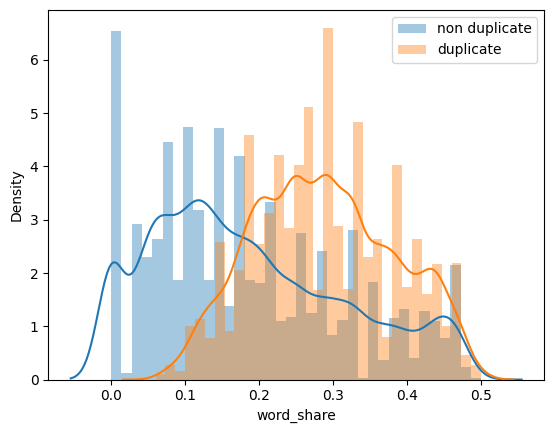

In [36]:
# word share
sns.distplot(new_df[new_df['is_duplicate'] == 0]['word_share'],label='non duplicate')
sns.distplot(new_df[new_df['is_duplicate'] == 1]['word_share'],label='duplicate')
plt.legend()
plt.show()

In [37]:
ques_df = new_df[['question1','question2']]
ques_df.head()

,question1,question2
134596,I can see a contacts display picture on WhatsA...,I deleted a contact from my phone can he still...
27109,What is the significance of 2^32 in computers?,Is a 3:2 program for computer science at Reed ...
369694,Which is the best Harry Potter book?,What's the best Harry Potter book?
292958,What makes a woman or girl unattractive?,Does being fat make you unattractive?
93000,How are the placements for M Tech Mechanical s...,How is placement scenario for m.tech students(...


In [38]:
final_df = new_df.drop(columns=['id','qid1','qid2','question1','question2'])
print(final_df.shape)
final_df.head()

(30000, 8)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share
134596,0,163,71,32,16,7,43,0.16
27109,0,46,63,8,12,1,20,0.05
369694,1,36,34,7,6,5,13,0.38
292958,0,40,37,7,6,1,13,0.08
93000,0,68,83,12,11,4,23,0.17


In [39]:
from sklearn.feature_extraction.text import CountVectorizer
# merge texts
questions = list(ques_df['question1']) + list(ques_df['question2'])

cv = CountVectorizer(max_features=3000)
q1_arr, q2_arr = np.vsplit(cv.fit_transform(questions).toarray(),2)

In [40]:
temp_df1 = pd.DataFrame(q1_arr, index= ques_df.index)
temp_df2 = pd.DataFrame(q2_arr, index= ques_df.index)
temp_df = pd.concat([temp_df1, temp_df2], axis=1)
temp_df.shape

(30000, 6000)

In [41]:
final_df = pd.concat([final_df, temp_df], axis=1)
print(final_df.shape)
final_df.head()

(30000, 6008)


,is_duplicate,q1_len,q2_len,q1_num_words,q2_num_words,word_common,word_total,word_share,0,1,...,2990,2991,2992,2993,2994,2995,2996,2997,2998,2999
134596,0,163,71,32,16,7,43,0.16,0,0,...,0,0,0,0,0,0,0,0,0,0
27109,0,46,63,8,12,1,20,0.05,0,0,...,0,0,0,0,0,0,0,0,0,0
369694,1,36,34,7,6,5,13,0.38,0,0,...,0,0,0,0,0,0,0,0,0,0
292958,0,40,37,7,6,1,13,0.08,0,0,...,1,0,0,0,0,0,0,0,0,0
93000,0,68,83,12,11,4,23,0.17,0,0,...,0,0,0,0,0,0,0,0,0,0


In [43]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(final_df.iloc[:,1:].values,final_df.iloc[:,0].values,test_size=0.2,random_state=1)

In [44]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
rf = RandomForestClassifier()
rf.fit(X_train,y_train)
y_pred = rf.predict(X_test)
accuracy_score(y_test,y_pred)

0.7688333333333334